In [2]:
from google.colab import files
uploaded = files.upload()

Saving unhealthy.jpg to unhealthy.jpg


In [3]:
from PIL import Image
import numpy as np

filename = list(uploaded.keys())[0]   # gets the name of the file you just uploaded
img = Image.open(filename)

print("Image size (width, height):", img.size)

img_array = np.array(img)
print("Array shape:", img_array.shape)
print("Data type:", img_array.dtype)

Image size (width, height): (437, 702)
Array shape: (702, 437, 3)
Data type: uint8


In [6]:
kaggle_token = "PASTE_YOUR_KAGGLE_TOKEN_HERE"

import os
os.makedirs('/root/.kaggle', exist_ok=True)
with open('/root/.kaggle/access_token', 'w') as f:
    f.write(kaggle_token)
os.system('chmod 600 /root/.kaggle/access_token')

0

In [7]:
!pip install -q kaggle
!kaggle datasets download -d abdallahalidev/plantvillage-dataset -p /content/raw --unzip

Dataset URL: https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset
License(s): CC-BY-NC-SA-4.0
100% 2.04G/2.04G [01:39<00:00, 22.0MB/s]



In [9]:
!ls "/content/raw/plantvillage dataset/color"

 Apple___Apple_scab
 Apple___Black_rot
 Apple___Cedar_apple_rust
 Apple___healthy
 Blueberry___healthy
'Cherry_(including_sour)___healthy'
'Cherry_(including_sour)___Powdery_mildew'
'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot'
'Corn_(maize)___Common_rust_'
'Corn_(maize)___healthy'
'Corn_(maize)___Northern_Leaf_Blight'
 Grape___Black_rot
'Grape___Esca_(Black_Measles)'
 Grape___healthy
'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)'
'Orange___Haunglongbing_(Citrus_greening)'
 Peach___Bacterial_spot
 Peach___healthy
 Pepper,_bell___Bacterial_spot
 Pepper,_bell___healthy
 Potato___Early_blight
 Potato___healthy
 Potato___Late_blight
 Raspberry___healthy
 Soybean___healthy
 Squash___Powdery_mildew
 Strawberry___healthy
 Strawberry___Leaf_scorch
 Tomato___Bacterial_spot
 Tomato___Early_blight
 Tomato___healthy
 Tomato___Late_blight
 Tomato___Leaf_Mold
 Tomato___Septoria_leaf_spot
'Tomato___Spider_mites Two-spotted_spider_mite'
 Tomato___Target_Spot
 Tomato___Tomato_mosaic_virus
 Tomato_

In [10]:
import os

base_path = "/content/raw/plantvillage dataset/color"
all_folders = os.listdir(base_path)

tomato_folders = [f for f in all_folders if f.startswith("Tomato")]

print(f"Found {len(tomato_folders)} tomato folders:")
for folder in sorted(tomato_folders):
    print(" -", folder)

Found 10 tomato folders:
 - Tomato___Bacterial_spot
 - Tomato___Early_blight
 - Tomato___Late_blight
 - Tomato___Leaf_Mold
 - Tomato___Septoria_leaf_spot
 - Tomato___Spider_mites Two-spotted_spider_mite
 - Tomato___Target_Spot
 - Tomato___Tomato_Yellow_Leaf_Curl_Virus
 - Tomato___Tomato_mosaic_virus
 - Tomato___healthy


In [11]:
for folder in sorted(tomato_folders):
    folder_path = os.path.join(base_path, folder)
    num_images = len(os.listdir(folder_path))
    print(f"{folder:55s} {num_images} images")

Tomato___Bacterial_spot                                 2127 images
Tomato___Early_blight                                   1000 images
Tomato___Late_blight                                    1909 images
Tomato___Leaf_Mold                                      952 images
Tomato___Septoria_leaf_spot                             1771 images
Tomato___Spider_mites Two-spotted_spider_mite           1676 images
Tomato___Target_Spot                                    1404 images
Tomato___Tomato_Yellow_Leaf_Curl_Virus                  5357 images
Tomato___Tomato_mosaic_virus                            373 images
Tomato___healthy                                        1591 images


In [12]:
dest = "/content/data/tomato"
os.makedirs(dest, exist_ok=True)

for folder in tomato_folders:
    source = os.path.join(base_path, folder)
    target = os.path.join(dest, folder)
    if not os.path.exists(target):
        os.symlink(source, target)

print("Done. Contents of", dest, ":")
print(os.listdir(dest))

Done. Contents of /content/data/tomato :
['Tomato___Early_blight', 'Tomato___Target_Spot', 'Tomato___Leaf_Mold', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Tomato_mosaic_virus', 'Tomato___Late_blight', 'Tomato___Septoria_leaf_spot', 'Tomato___Bacterial_spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___healthy']


In [13]:
import tensorflow as tf

IMG_SIZE = 160
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    dest,
    validation_split=0.15,
    subset="training",
    seed=42,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    dest,
    validation_split=0.15,
    subset="validation",
    seed=42,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
)

Found 18160 files belonging to 10 classes.
Using 15436 files for training.
Found 18160 files belonging to 10 classes.
Using 2724 files for validation.


In [14]:
class_names = train_ds.class_names
print(class_names)

['Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Tomato_mosaic_virus', 'Tomato___healthy']


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().shuffle(1000).prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)

In [15]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

num_classes = len(class_names)

base_model = MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights="imagenet")
base_model.trainable = False

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.15),
])

inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = data_augmentation(inputs)
x = preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(num_classes, activation="softmax")(x)

model = tf.keras.Model(inputs, outputs)
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [16]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
483/483 ━━━━━━━━━━━━━━━━━━━━ 34s 52ms/step - accuracy: 0.7394 - loss: 0.7905 - val_accuracy: 0.8087 - val_loss: 0.5728
Epoch 2/10
483/483 ━━━━━━━━━━━━━━━━━━━━ 20s 42ms/step - accuracy: 0.8514 - loss: 0.4431 - val_accuracy: 0.8253 - val_loss: 0.4920
Epoch 3/10
483/483 ━━━━━━━━━━━━━━━━━━━━ 20s 41ms/step - accuracy: 0.8671 - loss: 0.3911 - val_accuracy: 0.8198 - val_loss: 0.5172
Epoch 4/10
483/483 ━━━━━━━━━━━━━━━━━━━━ 21s 43ms/step - accuracy: 0.8779 - loss: 0.3648 - val_accuracy: 0.8656 - val_loss: 0.3974
Epoch 5/10
483/483 ━━━━━━━━━━━━━━━━━━━━ 20s 41ms/step - accuracy: 0.8862 - loss: 0.3400 - val_accuracy: 0.8447 - val_loss: 0.4574
Epoch 6/10
483/483 ━━━━━━━━━━━━━━━━━━━━ 21s 43ms/step - accuracy: 0.8871 - loss: 0.3293 - val_accuracy: 0.8645 - val_loss: 0.4030
Epoch 7/10
483/483 ━━━━━━━━━━━━━━━━━━━━ 22s 46ms/step - accuracy: 0.8887 - loss: 0.3274 - val_accuracy: 0.8454 - val_loss: 0.4612
Epoch 8/10
483/483 ━━━━━━━━━━━━━━━━━━━━ 20s 41ms/step - accuracy: 0.8883 - loss: 0.3251 - 

In [17]:
base_model.trainable = True

for layer in base_model.layers[:-40]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8
)

Epoch 1/8
483/483 ━━━━━━━━━━━━━━━━━━━━ 42s 64ms/step - accuracy: 0.7639 - loss: 0.9267 - val_accuracy: 0.8664 - val_loss: 0.4323
Epoch 2/8
483/483 ━━━━━━━━━━━━━━━━━━━━ 29s 60ms/step - accuracy: 0.8641 - loss: 0.4178 - val_accuracy: 0.8704 - val_loss: 0.4183
Epoch 3/8
483/483 ━━━━━━━━━━━━━━━━━━━━ 41s 60ms/step - accuracy: 0.8881 - loss: 0.3345 - val_accuracy: 0.8807 - val_loss: 0.3750
Epoch 4/8
483/483 ━━━━━━━━━━━━━━━━━━━━ 32s 65ms/step - accuracy: 0.9052 - loss: 0.2852 - val_accuracy: 0.8990 - val_loss: 0.3185
Epoch 5/8
483/483 ━━━━━━━━━━━━━━━━━━━━ 38s 60ms/step - accuracy: 0.9122 - loss: 0.2580 - val_accuracy: 0.9057 - val_loss: 0.2780
Epoch 6/8
483/483 ━━━━━━━━━━━━━━━━━━━━ 32s 65ms/step - accuracy: 0.9232 - loss: 0.2191 - val_accuracy: 0.9167 - val_loss: 0.2495
Epoch 7/8
483/483 ━━━━━━━━━━━━━━━━━━━━ 29s 60ms/step - accuracy: 0.9305 - loss: 0.1990 - val_accuracy: 0.9156 - val_loss: 0.2405
Epoch 8/8
483/483 ━━━━━━━━━━━━━━━━━━━━ 29s 60ms/step - accuracy: 0.9383 - loss: 0.1776 - val_accu

In [18]:
import os

os.makedirs('/content/model_out', exist_ok=True)
model.save('/content/model_out/tomato_cnn.keras')

print("Saved!")

Saved!


In [19]:
import json

# Same mapping used in the Flask app's predictor.py, so results connect up correctly
folder_to_key = {
    "Tomato___Bacterial_spot": "bacterial_spot",
    "Tomato___Early_blight": "early_blight",
    "Tomato___Late_blight": "late_blight",
    "Tomato___Leaf_Mold": "leaf_mold",
    "Tomato___Septoria_leaf_spot": "septoria_leaf_spot",
    "Tomato___Spider_mites Two-spotted_spider_mite": "spider_mites",
    "Tomato___Target_Spot": "target_spot",
    "Tomato___Tomato_Yellow_Leaf_Curl_Virus": "yellow_leaf_curl_virus",
    "Tomato___Tomato_mosaic_virus": "mosaic_virus",
    "Tomato___healthy": "healthy",
}

keys_by_index = [folder_to_key[name] for name in class_names]

with open('/content/model_out/class_indices.json', 'w') as f:
    json.dump({
        "img_size": IMG_SIZE,
        "class_names": class_names,
        "keys_by_index": keys_by_index,
    }, f, indent=2)

print(keys_by_index)

['bacterial_spot', 'early_blight', 'late_blight', 'leaf_mold', 'septoria_leaf_spot', 'spider_mites', 'target_spot', 'yellow_leaf_curl_virus', 'mosaic_virus', 'healthy']


In [20]:
from google.colab import files

files.download('/content/model_out/tomato_cnn.keras')
files.download('/content/model_out/class_indices.json')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
%%writefile /content/model_out/predict.py
import json
import numpy as np
from PIL import Image
import tensorflow as tf

model = tf.keras.models.load_model("tomato_cnn.keras")

with open("class_indices.json") as f:
    meta = json.load(f)

IMG_SIZE = meta["img_size"]
KEYS_BY_INDEX = meta["keys_by_index"]


def predict_disease(image_path):
    """Takes a path to a leaf photo, returns (predicted_class, confidence_percent)."""
    img = Image.open(image_path).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
    arr = np.expand_dims(np.array(img, dtype="float32"), axis=0)

    probabilities = model.predict(arr, verbose=0)[0]
    best_index = np.argmax(probabilities)

    predicted_class = KEYS_BY_INDEX[best_index]
    confidence = float(probabilities[best_index]) * 100

    return predicted_class, confidence

Writing /content/model_out/predict.py


In [22]:
from google.colab import files
files.download('/content/model_out/predict.py')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Example

In [23]:
from google.colab import files
uploaded = files.upload()

Saving healthy.jpg to healthy.jpg


In [25]:
test_image_path = list(uploaded.keys())[0]

predicted_class, confidence = predict_disease(test_image_path)

print("Predicted:", predicted_class)
print("Confidence:", round(confidence, 1), "%")

NameError: name 'predict_disease' is not defined

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

img = Image.open(test_image_path)
plt.imshow(img)
plt.axis('off')
plt.title(f"{predicted_class} ({confidence:.1f}%)")
plt.show()

In [29]:
%%writefile /content/model_out/predict.py
import os
import json
import numpy as np
from PIL import Image
import tensorflow as tf

# Folder this file lives in — makes the paths below work no matter
# where the calling code is running from
MODEL_DIR = os.path.dirname(os.path.abspath(__file__))

model = tf.keras.models.load_model(os.path.join(MODEL_DIR, "tomato_cnn.keras"))

with open(os.path.join(MODEL_DIR, "class_indices.json")) as f:
    meta = json.load(f)

IMG_SIZE = meta["img_size"]
KEYS_BY_INDEX = meta["keys_by_index"]


def predict_disease(image_path):
    """Takes a path to a leaf photo, returns (predicted_class, confidence_percent)."""
    img = Image.open(image_path).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
    arr = np.expand_dims(np.array(img, dtype="float32"), axis=0)

    probabilities = model.predict(arr, verbose=0)[0]
    best_index = np.argmax(probabilities)

    predicted_class = KEYS_BY_INDEX[best_index]
    confidence = float(probabilities[best_index]) * 100

    return predicted_class, confidence

Overwriting /content/model_out/predict.py


In [30]:
import sys
if 'predict' in sys.modules:
    del sys.modules['predict']
sys.path.append('/content/model_out')

from predict import predict_disease
print("Import worked!")

Import worked!


In [31]:
predicted_class, confidence = predict_disease(test_image_path)
print("Predicted:", predicted_class)
print("Confidence:", round(confidence, 1), "%")

Predicted: late_blight
Confidence: 100.0 %


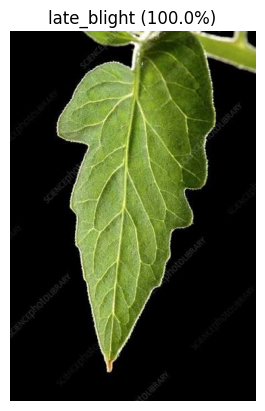

In [32]:
import matplotlib.pyplot as plt
from PIL import Image

img = Image.open(test_image_path)
plt.imshow(img)
plt.axis('off')
plt.title(f"{predicted_class} ({confidence:.1f}%)")
plt.show()

Original size: (364, 549)


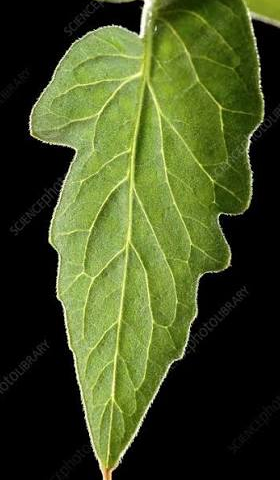

In [33]:
from PIL import Image

img = Image.open(test_image_path)
print("Original size:", img.size)

# crop tighter around the leaf — adjust these numbers based on where
# the leaf sits in your specific photo
cropped = img.crop((40, 20, 320, 500))  # left, top, right, bottom
cropped.save("cropped_test.jpg")
cropped

In [42]:
from google.colab import files
uploaded2 = files.upload()

Saving model image wb.jpg to model image wb.jpg


In [44]:
new_test_path = list(uploaded2.keys())[0]

predicted_class, confidence = predict_disease(new_test_path)
print("Predicted:", predicted_class)
print("Confidence:", round(confidence, 1), "%")

Predicted: late_blight
Confidence: 99.9 %


In [38]:
from predict import predict_disease, model, KEYS_BY_INDEX

In [45]:
import numpy as np
from PIL import Image

img = Image.open(new_test_path).convert("RGB").resize((160, 160))
arr = np.expand_dims(np.array(img, dtype="float32"), axis=0)

probabilities = model.predict(arr, verbose=0)[0]

for name, prob in sorted(zip(KEYS_BY_INDEX, probabilities), key=lambda x: -x[1]):
    print(f"{name:30s} {prob*100:.2f}%")

late_blight                    99.85%
septoria_leaf_spot             0.12%
early_blight                   0.01%
healthy                        0.01%
target_spot                    0.00%
leaf_mold                      0.00%
yellow_leaf_curl_virus         0.00%
spider_mites                   0.00%
bacterial_spot                 0.00%
mosaic_virus                   0.00%


In [47]:
from google.colab import files
uploaded3 = files.upload()   # pick the same white-background tomato leaf photo again

Saving model image wb.jpg to model image wb (1).jpg


In [50]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

new_test_path2 = list(uploaded3.keys())[0]

grad_model = tf.keras.Model(
    inputs=model.inputs,
    outputs=[model.get_layer(base_model.name).output, model.output]
)

img = Image.open(new_test_path2).convert("RGB").resize((160, 160))
img_array = np.expand_dims(np.array(img, dtype="float32"), axis=0)

with tf.GradientTape() as tape:
    conv_outputs, predictions = grad_model(img_array)
    class_idx = tf.argmax(predictions[0])
    loss = predictions[:, class_idx]

grads = tape.gradient(loss, conv_outputs)
pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
conv_outputs = conv_outputs[0]
heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
heatmap = tf.squeeze(heatmap)
heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Original")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img)
plt.imshow(heatmap, cmap='jet', alpha=0.5, extent=(0, 160, 160, 0))
plt.title("What the model looked at")
plt.axis('off')

plt.show()

KeyError: "Exception encountered when calling Functional.call().\n\n\x1b[1m137114557815392\x1b[0m\n\nArguments received by Functional.call():\n  • inputs=array([[[[255., 255., 255.],\n         [255., 255., 255.],\n         [255., 255., 255.],\n         ...,\n         [255., 255., 255.],\n         [255., 255., 255.],\n         [255., 255., 255.]],\n\n        [[255., 255., 255.],\n         [255., 255., 255.],\n         [255., 255., 255.],\n         ...,\n         [255., 255., 255.],\n         [255., 255., 255.],\n         [255., 255., 255.]],\n\n        [[255., 255., 255.],\n         [255., 255., 255.],\n         [255., 255., 255.],\n         ...,\n         [255., 255., 255.],\n         [255., 255., 255.],\n         [255., 255., 255.]],\n\n        ...,\n\n        [[  1.,   1.,   1.],\n         [  0.,   0.,   0.],\n         [  0.,   0.,   0.],\n         ...,\n         [  1.,   1.,   1.],\n         [  1.,   1.,   1.],\n         [  1.,   1.,   1.]],\n\n        [[  1.,   1.,   1.],\n        

In [51]:
seg_base_path = "/content/raw/plantvillage dataset/segmented"
seg_dest = "/content/data/tomato_segmented"
os.makedirs(seg_dest, exist_ok=True)

seg_tomato_folders = [f for f in os.listdir(seg_base_path) if f.startswith("Tomato")]

for folder in seg_tomato_folders:
    source = os.path.join(seg_base_path, folder)
    target = os.path.join(seg_dest, folder)
    if not os.path.exists(target):
        os.symlink(source, target)

print(f"Linked {len(seg_tomato_folders)} segmented tomato folders")

Linked 10 segmented tomato folders


In [52]:
train_ds_seg = tf.keras.utils.image_dataset_from_directory(
    seg_dest,
    validation_split=0.15,
    subset="training",
    seed=42,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
)

Found 18160 files belonging to 10 classes.
Using 15436 files for training.


In [53]:
def randomize_background(image, label):
    # Segmented images have a near-black background — build a mask
    # marking which pixels are "background" (all channels close to 0)
    is_background = tf.reduce_all(image < 15, axis=-1, keepdims=True)

    # Pick a random RGB color for this specific image
    random_color = tf.random.uniform([1, 1, 3], minval=0, maxval=255)

    # Where it's background, use the random color; elsewhere, keep the real leaf pixels
    new_image = tf.where(is_background, random_color, image)

    return new_image, label

train_ds_seg = train_ds_seg.map(randomize_background)

In [54]:
combined_train_ds = train_ds.concatenate(train_ds_seg)
combined_train_ds = combined_train_ds.shuffle(2000).prefetch(tf.data.AUTOTUNE)

In [55]:
base_model2 = MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights="imagenet")
base_model2.trainable = False

data_augmentation2 = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.2),
    layers.RandomContrast(0.25),
    layers.RandomBrightness(0.2),
])

inputs2 = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = data_augmentation2(inputs2)
x = preprocess_input(x)
x = base_model2(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs2 = layers.Dense(num_classes, activation="softmax")(x)

model2 = tf.keras.Model(inputs2, outputs2)

In [ ]:
model2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history2 = model2.fit(
    combined_train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
